In [ ]:
import pandas as pd
import pandas as pd
from tqdm import tqdm
from openai import OpenAI
import pickle


In [ ]:
output_file = "/content/drive/MyDrive/fix_systematic_review/Type_barriers/type_gpt_abs.xlsx"
df = pd.read_excel(output_file)

with open("/content/drive/MyDrive/fix_systematic_review/134_texts.pkl", "rb") as f:
    file_texts = pickle.load(f)


#Extract Barriers

In [ ]:
import pandas as pd
import re
from openai import OpenAI

client = OpenAI(api_key="api_key")



def call_openai(prompt, model="gpt-4o-mini"):
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": prompt}],
         temperature=0,
    max_tokens=2048,
    top_p=0.45
        )
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {e}"




In [ ]:
prompt_extract_barriers = """
You are a systematic review assistant.

Task: Extract all **clear, distinct barriers** mentioned in the text.
- Barriers may relate to conducting research, implementing Evidence-Based Practice (EBP), or both.
- Use short, paraphrased phrases (avoid long sentences).
- Ensure each barrier is listed only once (no duplicates or variations of the same idea).
- Normalize similar expressions into a single unified phrasing.
- Extract barriers ONLY if they are explicitly presented as findings, results, or conclusions by the authors.
- EXCLUDE any barriers mentioned only in the introduction, background, or related work (i.e., those attributed to previous studies or general literature).
- Do not infer or guess beyond the provided text.

Return ONLY a valid Python list of unique strings.

Text:
{text}
"""



In [ ]:
from tqdm import tqdm
import time

# Column names
type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"  # Column with the filename to get text from

# Save settings
save_interval = 10              # Save progress every N rows
output_file = "/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review.xlsx"  # Path to save progress file
df[f"barriers"] = ""

start_time = time.time()

# Loop over DataFrame rows with tqdm progress bar
for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):

    number_id = row.get(text_col, None) # Get filename for this row

    text = file_texts[number_id]
    prompt = prompt_extract_barriers.format(text=text)
    # Send prompt to the model and get the result
    result = call_openai(prompt)

    # Save the result in the corresponding MMAT_Q column
    df.at[i, f"barriers"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


In [ ]:
import pandas as pd

output_file = "/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review.xlsx"  # Path to save progress file
df = pd.read_excel(output_file)

In [ ]:
import ast
import re

def parse_barrier_cell(cell):
    if not isinstance(cell, str):
        return []
    match = re.search(r"\[.*\]", cell, re.S)
    if match:
        try:
            return ast.literal_eval(match.group(0))
        except Exception:
            return []
    return []

df["barriers_parsed"] = df["barriers"].apply(parse_barrier_cell)




In [ ]:
df.sample(20).to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_sample_20_new.xlsx")

In [ ]:
lst_bar = []
for i in df.barriers_parsed:
  lst_bar.extend(i)


In [ ]:
import re, ast


def chunk_list(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i+n]

lst_bar = []
for i in df.barriers_parsed:
    lst_bar.extend(i)

all_results = []


def extract_list_from_response(response: str):
    match = re.search(r"\[.*\]", response, re.DOTALL)
    if match:
        return ast.literal_eval(match.group(0))
    else:
        raise ValueError(f"Response not in expected format: {response}")

memory_themes = []

# for idx, chunk in enumerate(chunk_list(lst_bar, 100), start=1):
#     prompt = f"""
#     You are a systematic review assistant.

#     Task: Merge the new list of barriers into the existing themes, updating them as needed.

#     Existing themes (memory):
#     {memory_themes}

#     New barriers:
#     {chunk}

#     Instructions:
#     - Return a single updated list of 8–15 distinct, high-level themes.
#     - Each theme must be **clear, descriptive, and informative** (2–5 words).
#     - Merge overlapping or redundant themes into one unified theme.
#     - Avoid vague words like "support" or "issues" alone.
#     - Keep wording consistent across the list.
#     - Output ONLY a valid Python list of strings.
#     - Do NOT include code blocks, explanations, or formatting.

#     Example:
#     ["Funding and resource limitations",
#      "Organizational support deficiencies",
#      "Time and workload constraints",
#      "Knowledge and skills gaps",
#      "Negative attitudes toward research"]
#     """

#     result = call_openai(prompt)
#     memory_themes = extract_list_from_response(result)
#     all_results.append({"chunk": idx, "themes": memory_themes})


In [ ]:
import re, json, ast

def extract_list_from_response(response: str):
    """
    Extract a list of strings from the model response.
    Supports JSON arrays and Python-style lists.
    """
    match = re.search(r"\[.*\]", response, re.DOTALL)
    if not match:
        raise ValueError("Response not in expected format")
    text = match.group(0).strip()

    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass

    fixed = text.replace("'", '"')
    fixed = re.sub(r'(\w)" (?=\w)', r"\1' ", fixed)

    try:
        return json.loads(fixed)
    except json.JSONDecodeError:
        pass

    try:
        return ast.literal_eval(text)
    except Exception:
        return ast.literal_eval(fixed)

memory_themes = []
all_results = []

for idx, chunk in enumerate(chunk_list(lst_bar, 100), start=1):
    prompt = f"""
    You are a systematic review assistant.

    Current known themes:
    {memory_themes}

    New barriers:
    {chunk}

    Task:
    - Compare the new barriers to the current themes.
    - If any barrier introduces a genuinely new theme, return ONLY those new themes.
    - If none, return an empty list [].
    - Use 2–5 word descriptive names.
    - Return ONLY a valid JSON array of strings.
    """

    result = call_openai(prompt)
    new_items = extract_list_from_response(result)

    memory_themes.extend([t for t in new_items if t not in memory_themes])

    all_results.append({"chunk": idx, "added": new_items, "themes": memory_themes})


In [ ]:
import json

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/memory_themes.json", "w", encoding="utf-8") as f:
    json.dump(memory_themes, f, ensure_ascii=False, indent=2)

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/memory_themes.json", "r", encoding="utf-8") as f:
    memory_themes = json.load(f)


In [ ]:
import re
import ast

def extract_list_from_response(response: str):
    """
    Extracts a Python list of strings from the LLM response.
    Uses regex to find the first [ ... ] block.
    Falls back to line-based parsing if literal_eval fails.
    """
    match = re.search(r"\[.*\]", response, re.DOTALL)
    if match:
        text = match.group(0)
        try:
            return ast.literal_eval(text)
        except Exception:
            print("⚠️ literal_eval failed, trying fallback...")

    # --- Fallback ---
    # Split by lines, strip extra characters, keep only reasonable-length items
    lines = [line.strip(" '\"-•") for line in response.splitlines() if line.strip()]
    lines = [l for l in lines if len(l.split()) > 1 and len(l) < 100]
    return list(set(lines))


# --- Example usage ---

all_themes = memory_themes  # the long list of themes from your DataFrame

prompt = f"""
You are a systematic review assistant.

Here is a long list of barrier themes (with duplicates, synonyms, and overlaps):

{all_themes}

Task:
- Merge them into a **single unified list** of 25–35 high-level themes.
- Eliminate duplicates and near-duplicates.
- Each theme must be **clear, descriptive, and informative** (2–5 words).
- Each theme must represent a **specific barrier category**
  (e.g., "Organizational support deficiencies",
        "Knowledge and skills gaps",
        "Time and workload constraints").
- Do NOT output generic labels like "Barriers to research" or "Challenges to implementation".
- Use consistent wording across themes.
- Focus on categories broad enough to cover multiple barriers,
  but not so broad that important distinctions are lost.

IMPORTANT:
- Return ONLY a valid Python list of strings.
- Do NOT include code blocks, markdown, explanations, or quotes.
"""


# Call your LLM
result = call_openai(prompt)

# Extract the final unified themes
final_themes = extract_list_from_response(result)

print("Final merged themes:", final_themes)
print("Number of themes:", len(final_themes))


Final merged themes: ['Perceived value of research', 'Research accessibility issues', 'Resistance to change', 'Support for change deficiencies', 'Time and workload constraints', 'Methodological concerns', 'Research culture deficiencies', 'Peer and organizational support gaps', 'Authority and autonomy limitations', 'Overwhelming research information', 'Skills and knowledge gaps', 'Research infrastructure inadequacies', 'Cultural barriers to engagement', 'Perceived minimal benefits of change', 'Mentorship and guidance shortages', 'Work-life balance challenges', 'Clarity in research reporting', 'Funding and resource limitations', 'Collaboration and participation deficits', 'Training and education gaps', 'Negative attitudes towards research', 'Implementation clarity issues', 'Communication and information overload', 'Leadership and management support deficiencies', 'Isolation and lack of networking', 'Career development and advancement barriers', 'Inconsistencies in research application', 

In [ ]:
# import pandas as pd

# # Save as CSV
# pd.DataFrame(final_themes, columns=["Theme"]).to_csv("final_themes.csv", index=False, encoding="utf-8")

# print("✅ Themes saved to final_themes.csv")


import json

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/merged_memory_themes.json", "w", encoding="utf-8") as f:
    json.dump(final_themes, f, ensure_ascii=False, indent=2)

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/merged_memory_themes.json", "r", encoding="utf-8") as f:
    final_themes = json.load(f)


In [ ]:
from openai import OpenAI
import os, json


prompt = f"""
You are an expert in thematic analysis for systematic reviews.
Here is a list of barriers:

{final_themes}

Your task:
1. Identify overlapping or redundant barriers.
2. Merge them into 5–10 broader categories.
3. Return the result strictly as **valid JSON**, no explanations, no markdown.
Use this structure:
[
  {{"label": "string", "original_barriers": ["..."], "rationale": "string"}},
  ...
]
"""

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "system", "content": "You are a helpful assistant for thematic synthesis."},
        {"role": "user", "content": prompt}
    ],
    temperature=0.3
)

content = response.choices[0].message.content.strip()

result = json.loads(content)

for cat in result:
    print(f"Category: {cat['label']}")
    print(f"Barriers: {cat['original_barriers']}")
    print(f"Rationale: {cat['rationale']}")
    print("-" * 40)


Category: Research Value and Relevance
Barriers: ['Perceived value of research', 'Perceived minimal benefits of change', 'Research relevance and applicability concerns']
Rationale: These barriers relate to how research is perceived in terms of its value and relevance to practice.
----------------------------------------
Category: Accessibility and Infrastructure
Barriers: ['Research accessibility issues', 'Research infrastructure inadequacies', 'Technological and resource access issues']
Rationale: These barriers focus on the challenges related to accessing research and the necessary infrastructure to support it.
----------------------------------------
Category: Support and Collaboration
Barriers: ['Peer and organizational support gaps', 'Collaboration and participation deficits', 'Mentorship and guidance shortages', 'Leadership and management support deficiencies', 'Isolation and lack of networking']
Rationale: These barriers emphasize the lack of support and collaboration among peer

In [ ]:
import json
# with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/final.json", "w", encoding="utf-8") as f:
#     json.dump(result, f, ensure_ascii=False, indent=2)

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/final.json", "r", encoding="utf-8") as f:
    result = json.load(f)


In [ ]:
import ast
import re


df = pd.read_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review.xlsx")

def parse_barrier_cell(cell):
    if not isinstance(cell, str):
        return []
    match = re.search(r"\[.*\]", cell, re.S)
    if match:
        try:
            return ast.literal_eval(match.group(0))
        except Exception:
            return []
    return []

df["barriers_parsed"] = df["barriers"].apply(parse_barrier_cell)




In [ ]:
from openai import OpenAI
import json
from tqdm import tqdm


final_categories = [cat["label"] for cat in result]

def classify_single_barrier(barrier, categories):
    prompt = f"""
You are an expert in thematic analysis.

Task:
Assign the following barrier to the most appropriate category from the list.

Categories:
{categories}

Barrier:
"{barrier}"

Instructions:
- Return ONLY a valid string (the category label).
- Do not include explanations, JSON objects, lists, or code blocks.
"""

    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "system", "content": "You are a helpful assistant for thematic synthesis."},
            {"role": "user", "content": prompt}
        ],
        temperature=0
    )

    return response.choices[0].message.content.strip()

def classify_barriers_dict(barriers_list, categories):
    result_dict = {}
    for b in barriers_list:
        try:
            category = classify_single_barrier(b, categories)
            result_dict[b] = category
        except Exception as e:
            print(f"⚠️ Error classifying barrier '{b}': {e}")
            result_dict[b] = "Uncategorized"
    return result_dict

tqdm.pandas()

df["barrier_categories_dict"] = df["barriers_parsed"].progress_apply(
    lambda barriers: classify_barriers_dict(barriers, final_categories)
)

print("✅ Classification completed")
print(f"Total rows processed: {len(df)}")

print(df[["barriers_parsed", "barrier_categories_dict"]].head())


100%|██████████| 122/122 [29:57<00:00, 14.73s/it]

✅ Classification completed
Total rows processed: 122
                                     barriers_parsed  \
0  [lack of time to read research, inadequate fac...   
1  [lack of administrative support and mentorship...   
2  [lack of time, lack of nursing autonomy, lack ...   
3  [heavy workload, lack of funds, lack of suppor...   
4  [insufficient authority to instigate change, i...   

                             barrier_categories_dict  
0  {'lack of time to read research': 'Time and Wo...  
1  {'lack of administrative support and mentorshi...  
2  {'lack of time': 'Time and Workload Constraint...  
3  {'heavy workload': 'Time and Workload Constrai...  
4  {'insufficient authority to instigate change':...  


In [ ]:
df['new'] = df['barrier_categories_dict'].apply(lambda x: list(x.values()))

In [ ]:
df['barriers_parsed_len'] = df['barriers_parsed'].apply(lambda t: len(t))
df['barrier_categories_len'] = df['new'].apply(lambda t: len(t))

In [ ]:
df.to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_categories.xlsx", index=False)

In [ ]:
import pandas as pd

df = pd.read_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_categories.xlsx")

In [ ]:
import ast
df["barrier_categories_dict"] = df["barrier_categories_dict"].apply(ast.literal_eval)

In [ ]:
# list(mapping_df[mapping_df['category']=='Communication and Information Overload'].barrier)

lack of time to read research Time and Workload Constraints
inadequate facilities for implementation Accessibility and Infrastructure
lack of authority to change patient care procedures Cultural and Organizational Issues
isolation from knowledgeable colleagues Support and Collaboration
insufficient time on the job to implement new ideas Time and Workload Constraints
uncertainty about the generalizability of research results Research Value and Relevance
methodological inadequacies of research Research Value and Relevance
lack of clarity in implications for practice Research Application and Practice Gap
lack of replication of research Research Application and Practice Gap
conflicting results in literature Research Value and Relevance
uncertainty about believing research results Cultural and Organizational Issues
overwhelming amount of research information Communication and Information Overload
lack of awareness of research Communication and Information Overload
lack of support from admin

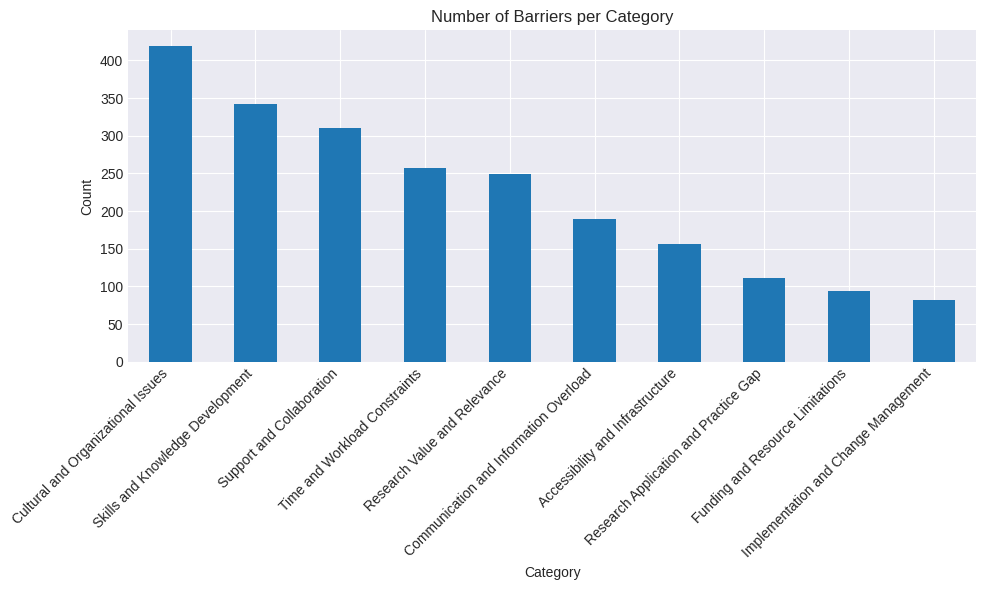

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

all_mappings = []
for row in df["barrier_categories_dict"]:
    if isinstance(row, dict):
        for barrier, category in row.items():
            print(barrier, category)
            all_mappings.append({"barrier": barrier, "category": category})

mapping_df = pd.DataFrame(all_mappings)

category_counts = mapping_df["category"].value_counts()

print(category_counts)

plt.figure(figsize=(10,6))
category_counts.plot(kind="bar")
plt.title("Number of Barriers per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


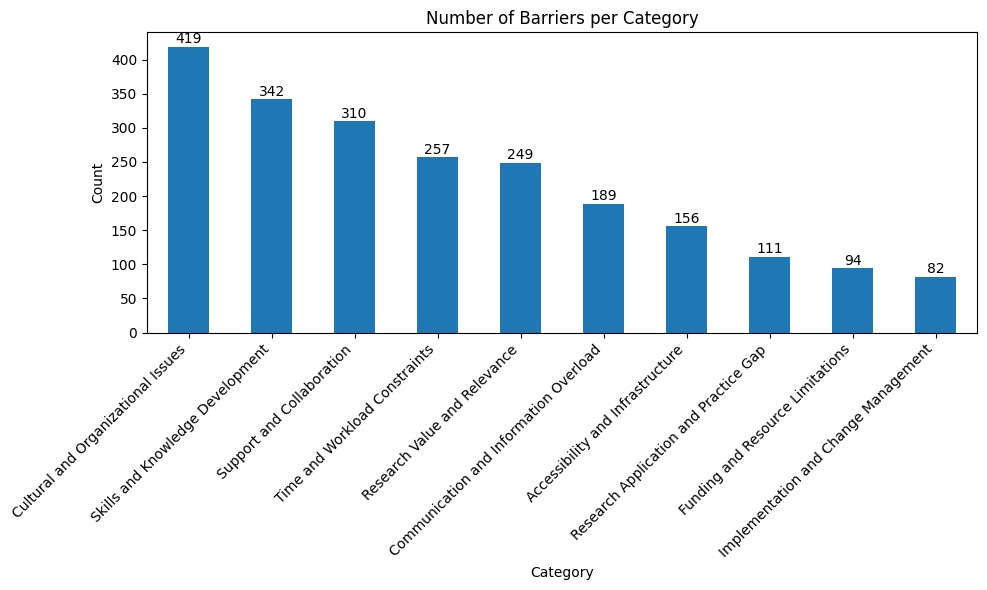

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

all_mappings = []
for row in df["barrier_categories_dict"]:
    if isinstance(row, dict):
        for barrier, category in row.items():
            all_mappings.append({"barrier": barrier, "category": category})

mapping_df = pd.DataFrame(all_mappings)

category_counts = mapping_df["category"].value_counts()

plt.figure(figsize=(10,6))
ax = category_counts.plot(kind="bar")

plt.title("Number of Barriers per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")

for i, v in enumerate(category_counts):
    ax.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


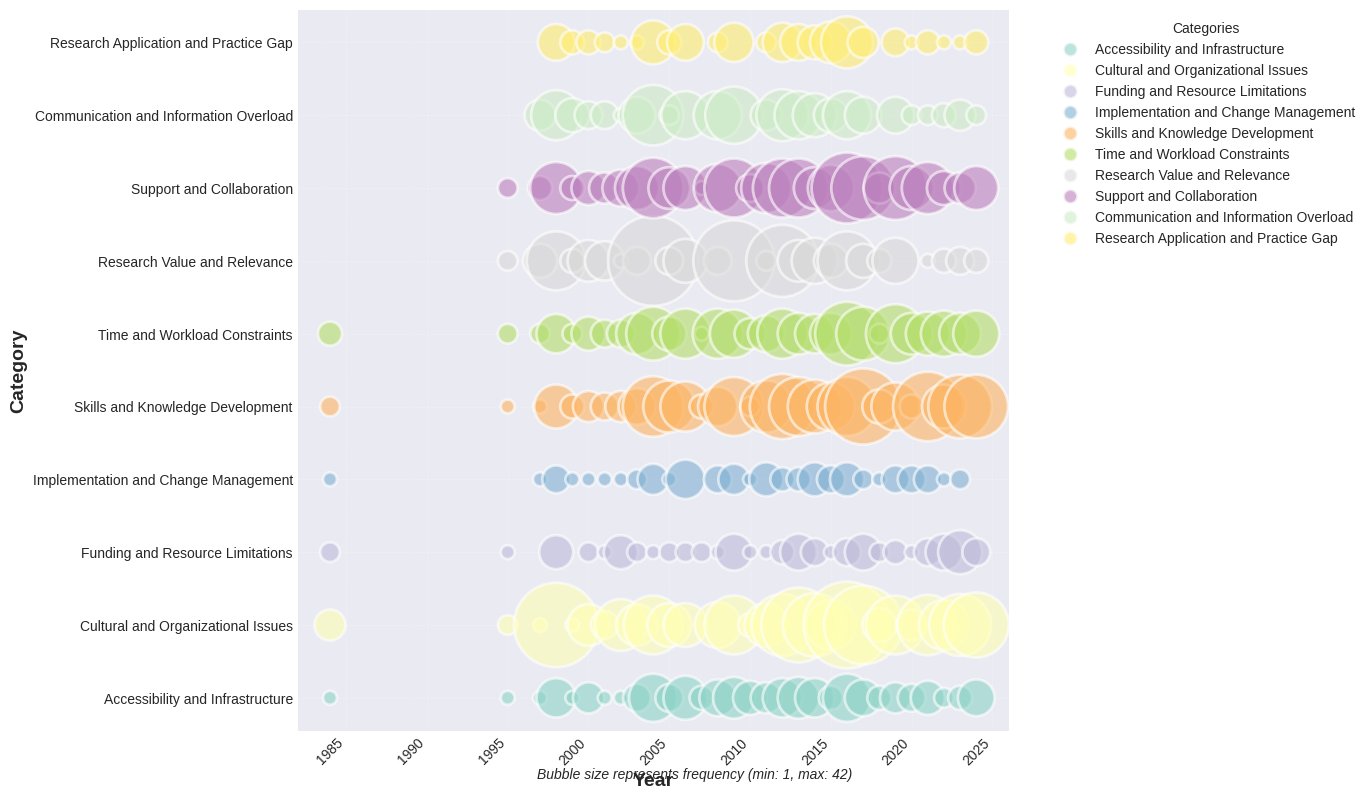

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# assuming df exists in environment
# build long format with barrier-category-year
all_mappings = []
for idx, row in df.iterrows():
    year = row.get("Year", None)
    cat_dict = row.get("barrier_categories_dict", None)
    if isinstance(cat_dict, dict):
        for barrier, category in cat_dict.items():
            all_mappings.append({"Year": year, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# aggregate counts for bubble size
bubble_df = mapping_df.groupby(["Year", "category"]).size().reset_index(name="count")

# Create figure with custom style
plt.style.use('seaborn-v0_8-darkgrid')
fig, ax = plt.subplots(figsize=(14, 8))

# Create color map for categories
categories = bubble_df["category"].unique()
colors = plt.cm.Set3(np.linspace(0, 1, len(categories)))
category_colors = dict(zip(categories, colors))

# Plot all bubbles at once (not per category)
scatter = ax.scatter(
    bubble_df["Year"],
    bubble_df["category"],
    s=bubble_df["count"] * 100,
    alpha=0.6,
    c=[category_colors[cat] for cat in bubble_df["category"]],
    edgecolors='white',
    linewidth=2
)

# Customize the plot
# ax.set_title("Distribution of Barrier Categories Over Time",
            #  fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel("Year", fontsize=14, fontweight='bold')
ax.set_ylabel("Category", fontsize=14, fontweight='bold')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add grid for better readability
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax.set_axisbelow(True)

# Create legend with actual categories (not sizes)
legend_elements = [plt.Line2D([0], [0], marker='o', color='w',
                              markerfacecolor=category_colors[cat],
                              markersize=10, label=cat, alpha=0.6,
                              markeredgecolor='white', markeredgewidth=2)
                   for cat in categories]
ax.legend(handles=legend_elements, title='Categories',
          bbox_to_anchor=(1.05, 1), loc='upper left')

# Add size reference in title or as text
size_text = f"Bubble size represents frequency (min: {bubble_df['count'].min()}, max: {bubble_df['count'].max()})"
plt.figtext(0.5, 0.02, size_text, ha='center', fontsize=10, style='italic')

plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.show()

In [ ]:
short_to_category = {
    "Culture & Organization": "Cultural and Organizational Issues",
    "Skills & Knowledge": "Skills and Knowledge Development",
    "Support & Collaboration": "Support and Collaboration",
    "Time & Workload": "Time and Workload Constraints",
    "Research Value": "Research Value and Relevance",
    "Information Overload": "Communication and Information Overload",
    "Access & Infrastructure": "Accessibility and Infrastructure",
    "Practice Gap": "Research Application and Practice Gap",
    "Resource Limitations": "Funding and Resource Limitations",
    "Adoption Resistance": "Implementation and Change Management"
}




In [ ]:

category_to_short = {v: k for k, v in short_to_category.items()}

# ---------------------------
# Replace category names
# ---------------------------
bubble_df = mapping_df.groupby(["Year", "category"]).size().reset_index(name="count")
bubble_df["category"] = bubble_df["category"].map(category_to_short)


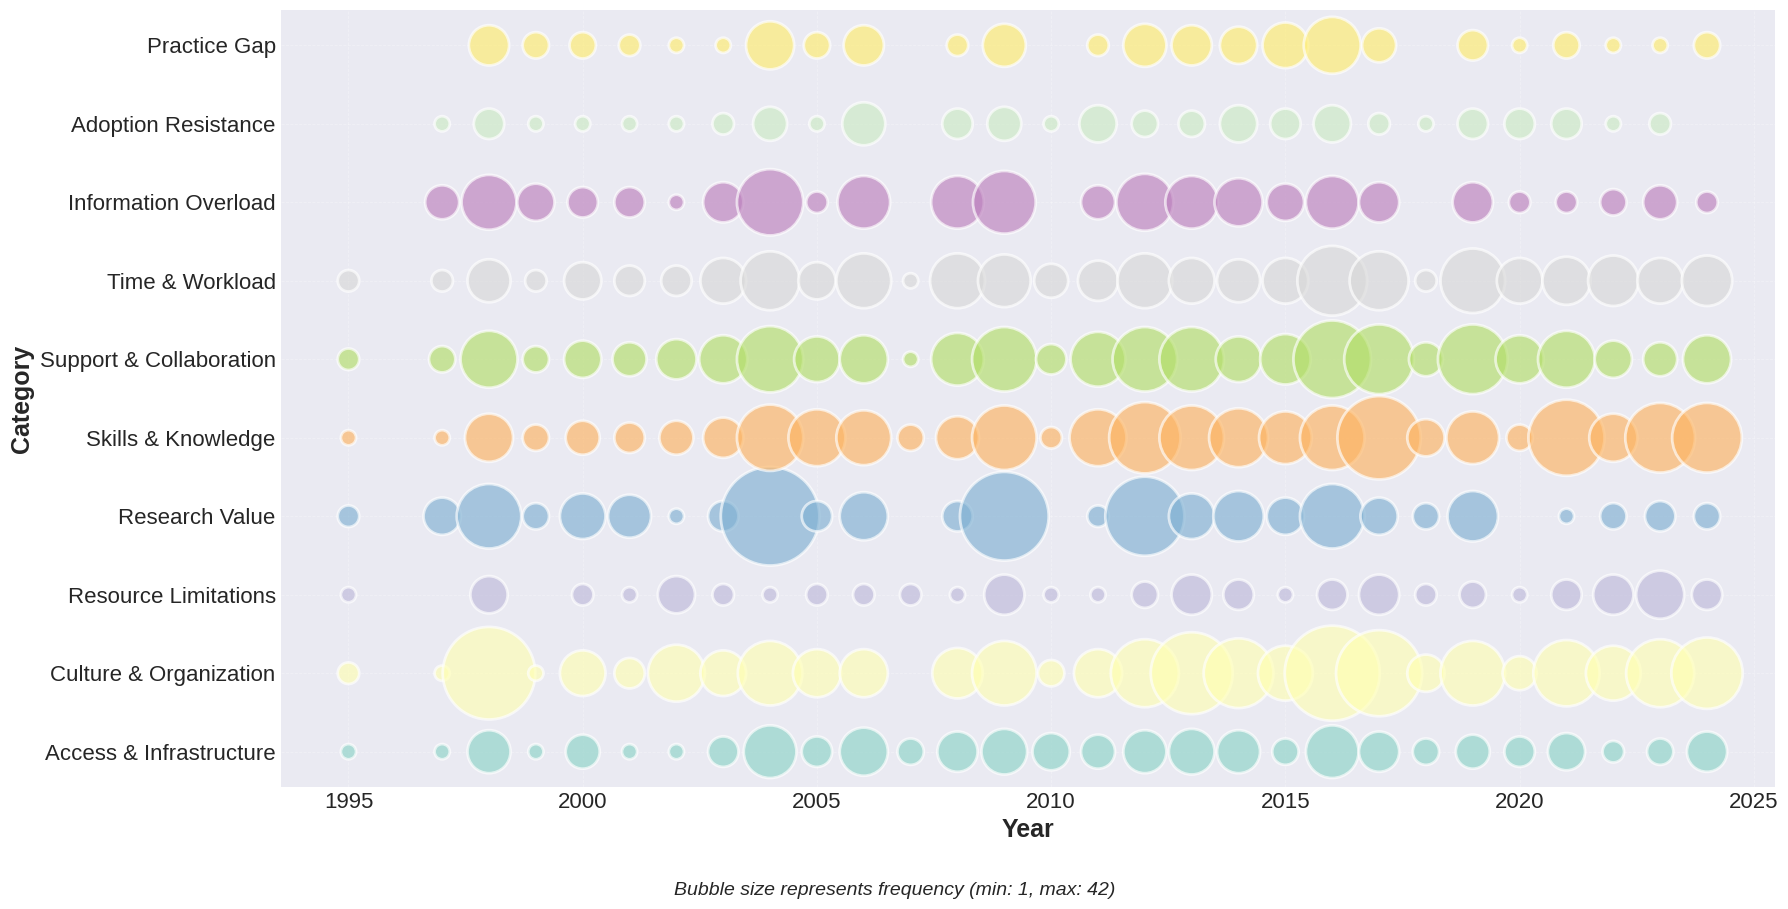

Minimum count: 1
Maximum count: 42
Total data points: 272


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------
# Convert dataframe into long format: one row per category-year mapping
# -------------------------------------------------------
all_mappings = []
for idx, row in df.iterrows():
    year = row.get("Year", None)
    cat_dict = row.get("barrier_categories_dict", None)
    if isinstance(cat_dict, dict):
        for barrier, category in cat_dict.items():
            all_mappings.append({"Year": year, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# Remove unwanted year before aggregation
mapping_df = mapping_df[mapping_df["Year"] != 1984]

# -------------------------------------------------------
# Aggregate counts for bubble sizes
# -------------------------------------------------------
bubble_df = mapping_df.groupby(["Year", "category"]).size().reset_index(name="count")
# bubble_df["category"] = bubble_df["category"].map(category_to_short)
bubble_df["category"] = bubble_df["category"].map(category_to_short).fillna(bubble_df["category"])

# -------------------------------------------------------
# Plot setup
# -------------------------------------------------------
plt.style.use('seaborn-v0_8-darkgrid')
fig, ax = plt.subplots(figsize=(18, 9))

# Assign colors to categories
categories = bubble_df["category"].unique()
colors = plt.cm.Set3(np.linspace(0, 1, len(categories)))
category_colors = dict(zip(categories, colors))

# -------------------------------------------------------
# Scatter plot (bubble chart)
# -------------------------------------------------------
scatter = ax.scatter(
    bubble_df["Year"],
    bubble_df["category"],
    s=bubble_df["count"] * 120,   # slightly larger bubbles
    alpha=0.65,
    c=[category_colors[cat] for cat in bubble_df["category"]],
    edgecolors='white',
    linewidth=2
)

# -------------------------------------------------------
# Axis labels
# -------------------------------------------------------
ax.set_xlabel("Year", fontsize=18, fontweight='bold')
ax.set_ylabel("Category", fontsize=18, fontweight='bold')

# Increase tick label size for x and y axes
ax.tick_params(axis='both', which='major', labelsize=16)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Grid styling
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.6)
ax.set_axisbelow(True)

# -------------------------------------------------------
# Legend construction
# -------------------------------------------------------
legend_elements = [
    plt.Line2D(
        [0], [0], marker='o', color='w',
        markerfacecolor=category_colors[cat],
        markersize=10, label=cat, alpha=0.7,
        markeredgecolor='white', markeredgewidth=2
    )
    for cat in categories
]

# legend = ax.legend(
#     handles=legend_elements,
#     title='Categories',
#     title_fontsize=18,
#     prop={'size': 16},
#     loc='upper left',
#     bbox_to_anchor=(1.05, 1),
#     frameon=True
# )

# Make legend title bold
# legend.get_title().set_fontweight('bold')

# Increase legend marker sizes
# for h in legend_elements:
#     h.set_markersize(18)

# -------------------------------------------------------
# Bubble size annotation
# -------------------------------------------------------
min_count = int(bubble_df['count'].min())
max_count = int(bubble_df['count'].max())
size_text = f"Bubble size represents frequency (min: {min_count}, max: {max_count})"

plt.figtext(0.5, 0.0, size_text, ha='center', fontsize=14, style='italic')

# Adjust spacing
plt.subplots_adjust(bottom=0.18)
plt.tight_layout()
plt.subplots_adjust(bottom=0.12)

# -------------------------------------------------------
# Show the plot
# -------------------------------------------------------
plt.show()

# Print summary statistics
print(f"Minimum count: {min_count}")
print(f"Maximum count: {max_count}")
print(f"Total data points: {len(bubble_df)}")


/tmp/ipython-input-1392171535.py:137: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels, fontsize=15, fontweight='500')


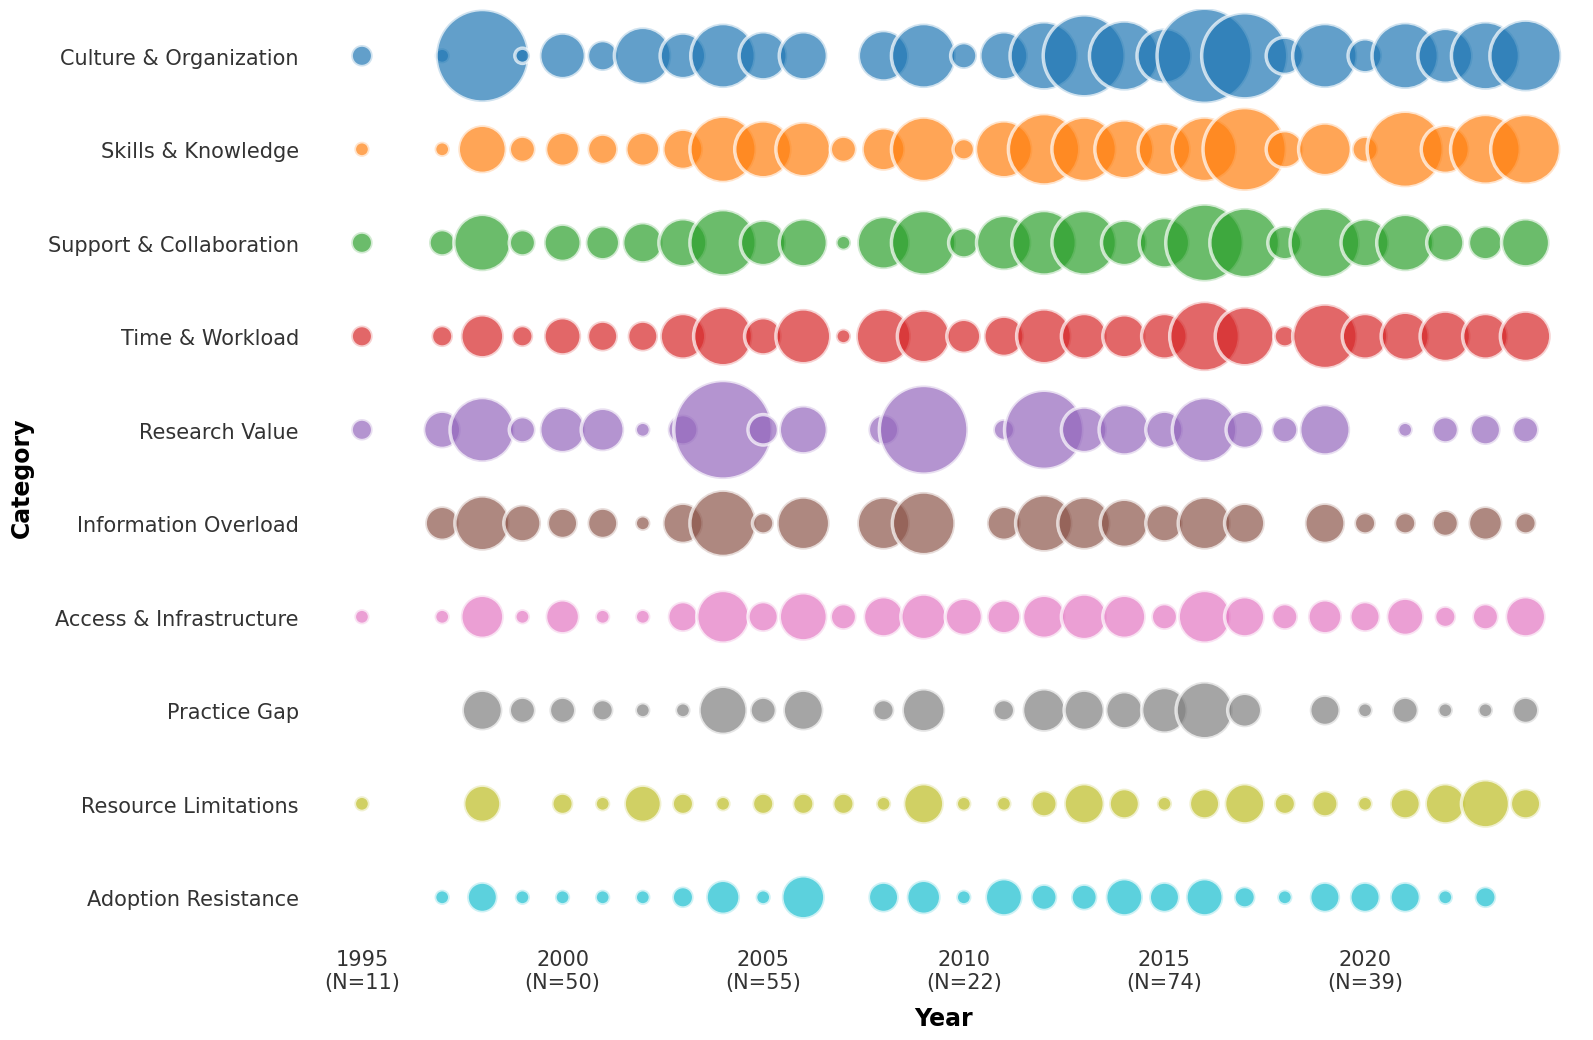

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------
# Convert dataframe into long format: one row per category-year mapping
# -------------------------------------------------------
all_mappings = []
for idx, row in df.iterrows():
    year = row.get("Year", None)
    cat_dict = row.get("barrier_categories_dict", None)
    if isinstance(cat_dict, dict):
        for barrier, category in cat_dict.items():
            all_mappings.append({"Year": year, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# Remove unwanted year before aggregation
mapping_df = mapping_df[mapping_df["Year"] != 1984]

# -------------------------------------------------------
# Shortened category mapping
# -------------------------------------------------------
short_to_category = {
    "Culture & Organization": "Cultural and Organizational Issues",
    "Skills & Knowledge": "Skills and Knowledge Development",
    "Support & Collaboration": "Support and Collaboration",
    "Time & Workload": "Time and Workload Constraints",
    "Research Value": "Research Value and Relevance",
    "Information Overload": "Communication and Information Overload",
    "Access & Infrastructure": "Accessibility and Infrastructure",
    "Practice Gap": "Research Application and Practice Gap",
    "Resource Limitations": "Funding and Resource Limitations",
    "Adoption Resistance": "Implementation and Change Management"
}

category_to_short = {v: k for k, v in short_to_category.items()}

# -------------------------------------------------------
# Aggregate counts for bubble sizes
# -------------------------------------------------------
bubble_df = mapping_df.groupby(["Year", "category"]).size().reset_index(name="count")

# Replace long category names with short ones
bubble_df["category"] = bubble_df["category"].map(category_to_short)

# -------------------------------------------------------
# Define Y-axis order - TOP to BOTTOM
# -------------------------------------------------------
desired_order = [
    "Culture & Organization",        # Top (Y=9)
    "Skills & Knowledge",            # Y=8
    "Support & Collaboration",       # Y=7
    "Time & Workload",              # Y=6
    "Research Value",               # Y=5
    "Information Overload",         # Y=4
    "Access & Infrastructure",      # Y=3
    "Practice Gap",                 # Y=2
    "Resource Limitations",         # Y=1
    "Adoption Resistance"           # Bottom (Y=0)
]

# Create position mapping
category_to_position = {cat: len(desired_order) - 1 - i for i, cat in enumerate(desired_order)}

# Map categories to their Y positions
bubble_df["y_position"] = bubble_df["category"].map(category_to_position)

# -------------------------------------------------------
# Plot setup with clean styling
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 11))

# Set clean background
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Assign beautiful colors to categories
colors = plt.cm.tab10(np.linspace(0, 1, len(desired_order)))
category_colors = dict(zip(desired_order, colors))

# -------------------------------------------------------
# Scatter plot (bubble chart)
# -------------------------------------------------------
scatter = ax.scatter(
    bubble_df["Year"],
    bubble_df["y_position"],
    s=bubble_df["count"] * 120,
    alpha=0.7,
    c=[category_colors[cat] for cat in bubble_df["category"]],
    edgecolors='white',
    linewidth=2.5
)

# -------------------------------------------------------
# Set Y-axis ticks and labels
# -------------------------------------------------------
y_positions = list(range(len(desired_order)))
ax.set_yticks(y_positions)
ax.set_yticklabels(list(reversed(desired_order)), fontsize=14, fontweight='500')

# -------------------------------------------------------
# Axis labels with clean styling
# -------------------------------------------------------
ax.set_xlabel("Year", fontsize=17, fontweight='bold', labelpad=10)
ax.set_ylabel("Category", fontsize=17, fontweight='bold', labelpad=10)

# Clean tick styling
ax.tick_params(axis='both', which='major', labelsize=15, length=0, colors='#333333')
plt.xticks(rotation=0)

# NO GRID - removed
ax.grid(False)

# Set Y-axis limits
ax.set_ylim(-0.5, len(desired_order) - 0.5)

# Remove ALL spines
for spine in ax.spines.values():
    spine.set_visible(False)

# -------------------------------------------------------
# Replace X-axis tick labels with "Year (N=xx)"
# -------------------------------------------------------
year_counts = bubble_df.groupby("Year")["count"].sum()

xticks = ax.get_xticks()
new_labels = []

for xtick in xticks:
    year = int(xtick)
    if year in year_counts.index:
        new_labels.append(f"{year}\n(N={year_counts.loc[year]})")
    else:
        new_labels.append("")

ax.set_xticklabels(new_labels, fontsize=15, fontweight='500')

# -------------------------------------------------------
# Adjust spacing
# -------------------------------------------------------
plt.tight_layout()
plt.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.1)

# -------------------------------------------------------
# Show the plot
# -------------------------------------------------------
plt.savefig("barrier_bubble_chart.png", dpi=600, bbox_inches="tight")

plt.show()


In [ ]:
bubble_df["category"].unique()


['Access & Infrastructure', 'Culture & Organization', 'Resource Limitations', 'Research Value', 'Skills & Knowledge', 'Support & Collaboration', 'Time & Workload', 'Information Overload', 'Adoption Resistance', 'Practice Gap']
Categories (10, object): ['Adoption Resistance' < 'Resource Limitations' < 'Practice Gap' <
                          'Access & Infrastructure' ... 'Time & Workload' < 'Support & Collaboration' <
                          'Skills & Knowledge' < 'Culture & Organization']

In [ ]:
df_2= pd.read_excel('/content/drive/MyDrive/fix_systematic_review/goal/final.xlsx')
df['quality_label'] = df_2['quality_label']

<Figure size 1000x600 with 0 Axes>

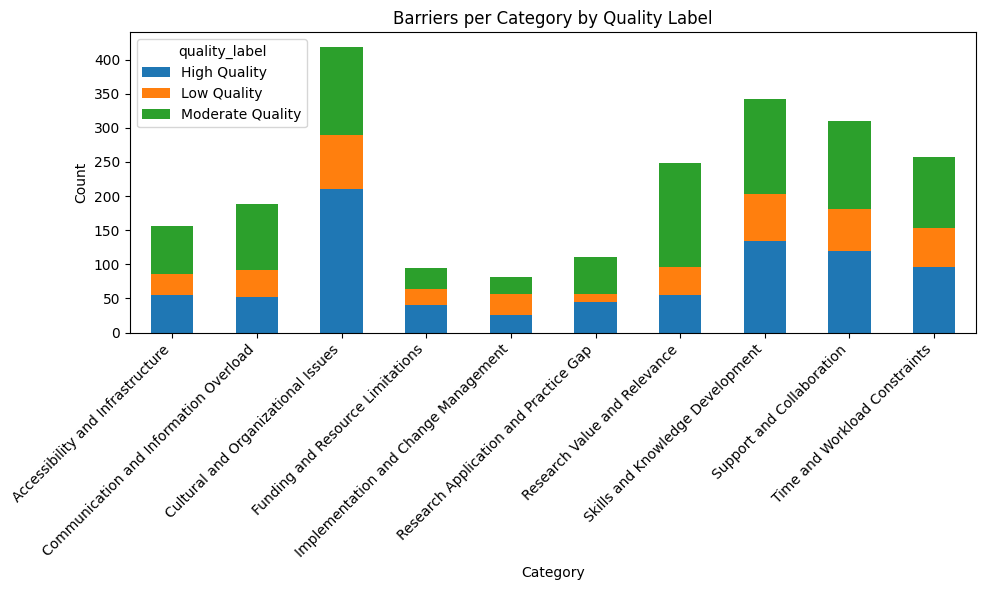

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Flatten barrier-category mappings
all_mappings = []
for idx, row in df["barrier_categories_dict"].items():
    if isinstance(row, dict):
        for barrier, category in row.items():
            all_mappings.append({
                "index": idx,
                "barrier": barrier,
                "category": category
            })

mapping_df = pd.DataFrame(all_mappings)

# Add quality_label from df_2
mapping_df = mapping_df.merge(
    df_2[["quality_label"]],
    left_on="index", right_index=True, how="left"
)

# Group counts by category and quality label
stack_data = mapping_df.groupby(["category", "quality_label"]).size().unstack(fill_value=0)

# Plot stacked bar
plt.figure(figsize=(10,6))
stack_data.plot(kind="bar", stacked=True, figsize=(10,6))

plt.title("Barriers per Category by Quality Label")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


<Figure size 1200x700 with 0 Axes>

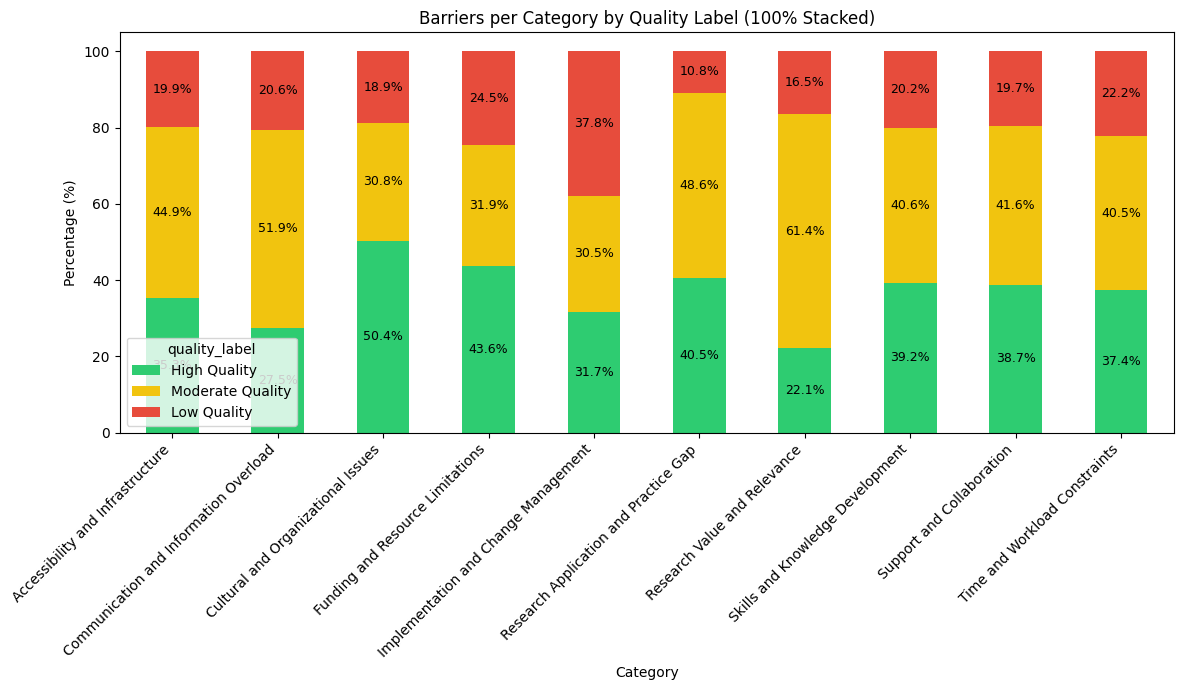

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# ✅ Convert stringified dicts to real dicts (if needed)
df["barrier_categories_dict"] = df["barrier_categories_dict"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# ✅ Flatten barrier → category mappings
all_mappings = []
for i, row in df["barrier_categories_dict"].items():
    if isinstance(row, dict):
        for barrier, category in row.items():
            all_mappings.append({"index": i, "barrier": barrier, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# ✅ Add quality_label
mapping_df = mapping_df.merge(
    df_2[["quality_label"]],
    left_on="index", right_index=True, how="left"
)

# ✅ Count categories per quality
stack_data = mapping_df.groupby(["category", "quality_label"]).size().unstack(fill_value=0)

# ✅ Normalize to 100%
stack_data_pct = stack_data.div(stack_data.sum(axis=1), axis=0) * 100

# ✅ Better color palette
color_map = {
    "High Quality": "#2ECC71",       # Green, clean
    "Moderate Quality": "#F1C40F",   # Gold/Yellow
    "Low Quality": "#E74C3C"         # Professional red
}

# ✅ Ensure proper order
stack_data_pct = stack_data_pct[["High Quality", "Moderate Quality", "Low Quality"]]

plt.figure(figsize=(12,7))
ax = stack_data_pct.plot(kind="bar", stacked=True, figsize=(12,7),
                         color=[color_map[col] for col in stack_data_pct.columns])

plt.title("Barriers per Category by Quality Label (100% Stacked)")
plt.xlabel("Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")

# ✅ Add labels
for idx, category in enumerate(stack_data_pct.index):
    y_offset = 0
    for label in stack_data_pct.columns:
        value = stack_data_pct.loc[category, label]
        if value > 0:
            ax.text(idx, y_offset + value/2, f"{value:.1f}%",
                    ha="center", va="center", fontsize=9)
            y_offset += value

plt.tight_layout()
plt.show()


In [ ]:
short_to_category = {
    "Culture & Organization": "Cultural and Organizational Issues",
    "Skills & Knowledge": "Skills and Knowledge Development",
    "Support & Collaboration": "Support and Collaboration",
    "Time & Workload": "Time and Workload Constraints",
    "Research Value": "Research Value and Relevance",
    "Information Overload": "Communication and Information Overload",
    "Access & Infrastructure": "Accessibility and Infrastructure",
    "Practice Gap": "Research Application and Practice Gap",
    "Resource Limitations": "Funding and Resource Limitations",
    "Adoption Resistance": "Implementation and Change Management"
}

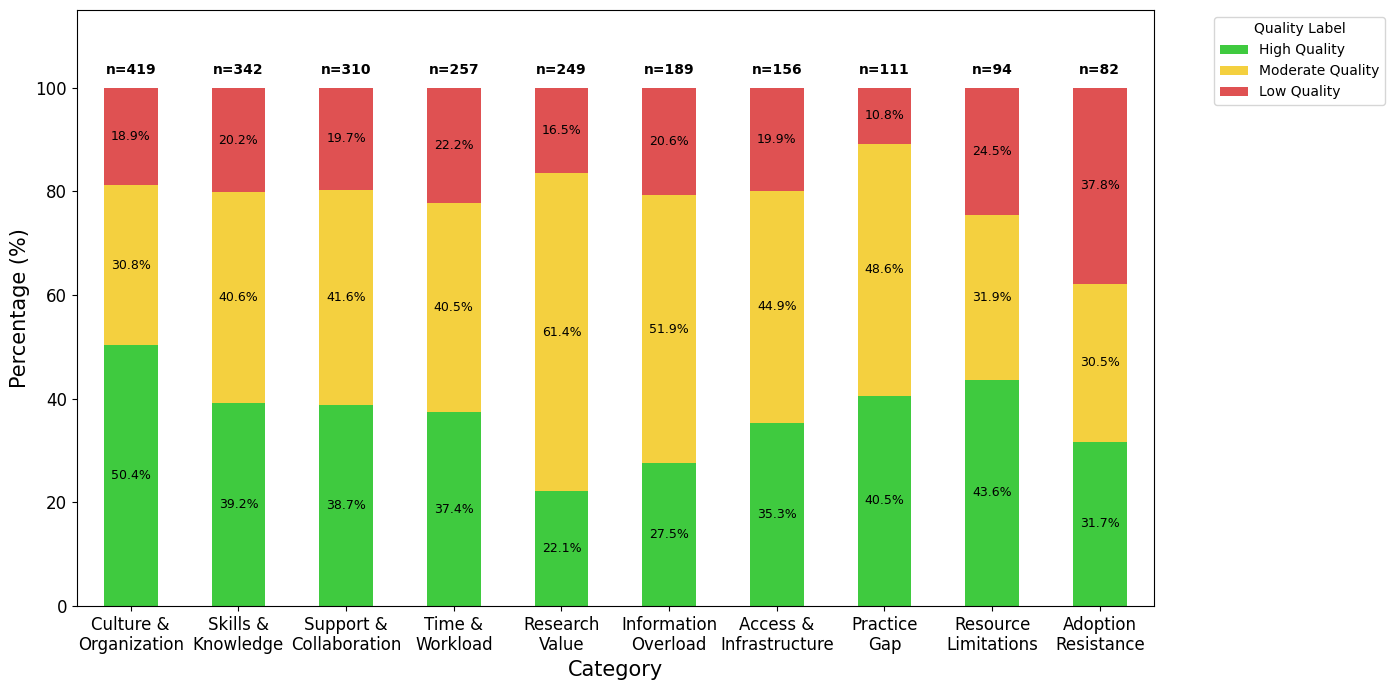

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# -------------------------------------------------------
# Shortened category mapping
# -------------------------------------------------------
short_to_category = {
    "Culture & Organization": "Cultural and Organizational Issues",
    "Skills & Knowledge": "Skills and Knowledge Development",
    "Support & Collaboration": "Support and Collaboration",
    "Time & Workload": "Time and Workload Constraints",
    "Research Value": "Research Value and Relevance",
    "Information Overload": "Communication and Information Overload",
    "Access & Infrastructure": "Accessibility and Infrastructure",
    "Practice Gap": "Research Application and Practice Gap",
    "Resource Limitations": "Funding and Resource Limitations",
    "Adoption Resistance": "Implementation and Change Management"
}

# Reverse mapping (full → short) for consistent category names
category_to_short = {v: k for k, v in short_to_category.items()}

# -------------------------------------------------------
# Convert stringified dicts to actual dicts
# -------------------------------------------------------
df["barrier_categories_dict"] = df["barrier_categories_dict"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# -------------------------------------------------------
# Flatten mapping: barrier → category
# -------------------------------------------------------
all_mappings = []
for i, row in df["barrier_categories_dict"].items():
    if isinstance(row, dict):
        for barrier, category in row.items():
            # Map category to short name
            short_cat = category_to_short.get(category, category)
            all_mappings.append({"index": i, "barrier": barrier, "category": short_cat})

mapping_df = pd.DataFrame(all_mappings)

# -------------------------------------------------------
# Add quality_label
# -------------------------------------------------------
mapping_df = mapping_df.merge(
    df_2[["quality_label"]],
    left_on="index", right_index=True, how="left"
)

# -------------------------------------------------------
# Count items per category/quality
# -------------------------------------------------------
stack_data = mapping_df.groupby(["category", "quality_label"]).size().unstack(fill_value=0)

# Save absolute counts
absolute_counts = stack_data.sum(axis=1)

# Normalize to percentages
stack_data_pct = stack_data.div(stack_data.sum(axis=1), axis=0) * 100

# Reorder quality columns
stack_data_pct = stack_data_pct[["High Quality", "Moderate Quality", "Low Quality"]]

# Sort categories by total count
stack_data_pct = stack_data_pct.loc[absolute_counts.sort_values(ascending=False).index]
absolute_counts = absolute_counts.loc[stack_data_pct.index]

# -------------------------------------------------------
# Colors
# -------------------------------------------------------
# color_map = {
#     "High Quality": "#2ECC71",   # Green
#     "Moderate Quality": "#F1C40F",  # Yellow/Gold
#     "Low Quality": "#E74C3C"       # Red
# }
tab10 = plt.cm.tab10
color_map = {
    "High Quality": tab10(2),   # ירוק-טורקיז
    "Moderate Quality": "#F1C40F",  # צהוב אמיתי
    "Low Quality": tab10(3)       # אדום
}
def lighten(color, amount=0.4):
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    new_c = colorsys.hls_to_rgb(c[0], min(1, amount * c[1] + (1-amount)), c[2])
    return new_c

# ואז:
color_map = {
    "High Quality": lighten(tab10(2), 0.8),
    "Moderate Quality": lighten("#F1C40F", 0.8),
    "Low Quality": lighten(tab10(3), 0.8)
}

# -------------------------------------------------------
# Multi-line labels for X-axis
# -------------------------------------------------------
label_mapping = {
    "Culture & Organization": "Culture &\nOrganization",
    "Skills & Knowledge": "Skills &\nKnowledge",
    "Support & Collaboration": "Support &\nCollaboration",
    "Time & Workload": "Time &\nWorkload",
    "Research Value": "Research\nValue",
    "Information Overload": "Information\nOverload",
    "Access & Infrastructure": "Access &\nInfrastructure",
    "Practice Gap": "Practice\nGap",
    "Resource Limitations": "Resource\nLimitations",
    "Adoption Resistance": "Adoption\nResistance"
}

# -------------------------------------------------------
# Plot
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 7))

stack_data_pct.plot(
    kind="bar",
    stacked=True,
    color=[color_map[col] for col in stack_data_pct.columns],
    ax=ax
)

plt.xlabel("Category", fontsize=15)
plt.ylabel("Percentage (%)", fontsize=15)

# Apply multi-line labels
new_labels = [label_mapping.get(cat, cat) for cat in stack_data_pct.index]
ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=12)

# Legend outside
plt.legend(title="Quality Label", bbox_to_anchor=(1.05, 1), loc="upper left")

# -------------------------------------------------------
# Add % labels inside bars
# -------------------------------------------------------
for idx, category in enumerate(stack_data_pct.index):
    y_offset = 0
    for label in stack_data_pct.columns:
        value = stack_data_pct.loc[category, label]
        if value > 0:
            ax.text(idx, y_offset + value/2, f"{value:.1f}%",
                    ha="center", va="center", fontsize=9)
            y_offset += value

# -------------------------------------------------------
# Add total counts above bars
# -------------------------------------------------------
for idx, total in enumerate(absolute_counts):
    ax.text(idx, 102, f"n={total}", ha="center",
            va="bottom", fontsize=10, fontweight="bold")

plt.ylim(0, 115)
plt.tight_layout()
ax.tick_params(axis='y', labelsize=12)

plt.savefig("barriers_graph_bar.png", dpi=600, bbox_inches="tight")

plt.show()

In [ ]:
df_2= pd.read_excel('/content/drive/MyDrive/fix_systematic_review/goal/final.xlsx')
df['quality_label'] = df_2['quality_label']

In [ ]:



import pandas as pd
path = "/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_categories.xlsx"
df= pd.read_excel(path)

In [ ]:
import pandas as pd
import random
import json


sampled_df = df.sample(n=25, random_state=42)

pairs = []
for _, row in sampled_df.iterrows():
    d = row["barrier_categories_dict"]

    if isinstance(d, str):
        try:
            d = json.loads(d.replace("'", '"'))
        except Exception as e:
            continue

    if isinstance(d, dict) and d:
        key = random.choice(list(d.keys()))
        value = d[key]
        pairs.append({
            "doi": row["barrier_categories"],
            "barrier": key,
            "category": value
        })

pairs_df = pd.DataFrame(pairs)



In [ ]:
pairs_df.to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/random_barriers_20.xlsx", index=False)

In [ ]:
pairs_df

,doi,barrier,category
0,"['Time and Workload Constraints', 'Time and Wo...",relevant literature is not compiled in one place,Communication and Information Overload
1,"['Time and workload constraints', 'Cultural an...",Insufficient opportunities for professional de...,Skills and Knowledge Development
2,"['Cultural and Organizational Issues', 'Commun...",poor presentation and readability of articles,Communication and Information Overload
3,"['Implementation and Change Management', 'Time...",nurse sees little benefit for self,Cultural and Organizational Issues
4,"['Implementation and Change Management', 'Impl...",unexpected discharges,Implementation and Change Management
5,"['Cultural and Organizational Issues', 'Fundin...",prolonged underfunding of nursing research,Funding and Resource Limitations
6,"['Time and Workload Constraints', 'Time and Wo...",time constraints,Time and Workload Constraints
7,"['Time and Workload Constraints', 'Time and Wo...",insufficient time to implement new ideas,Time and Workload Constraints
8,"['Skills and Knowledge Development', 'Research...",Not using the EBP process in daily practice,Research Application and Practice Gap
9,"['Time and workload constraints', 'Time and wo...",lack of awareness of the research,Communication and Information Overload
